In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [57]:
# Part 1: Data Understanding:
data = pd.read_csv("Dry_Bean_Dataset.csv")
data

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653247,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON


In [58]:
print(data.head(5))

    Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRation  \
0  28395    610.291       208.178117       173.888747      1.197191   
1  28734    638.018       200.524796       182.734419      1.097356   
2  29380    624.110       212.826130       175.931143      1.209713   
3  30008    645.884       210.557999       182.516516      1.153638   
4  30140    620.134       201.847882       190.279279      1.060798   

   Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  roundness  \
0      0.549812       28715     190.141097  0.763923  0.988856   0.958027   
1      0.411785       29172     191.272751  0.783968  0.984986   0.887034   
2      0.562727       29690     193.410904  0.778113  0.989559   0.947849   
3      0.498616       30724     195.467062  0.782681  0.976696   0.903936   
4      0.333680       30417     195.896503  0.773098  0.990893   0.984877   

   Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4  Class  
0     0.913358      0.007332  

In [59]:
print(data.shape)
print(data.shape[0]) # rows
print(data.shape[1]) # columns

(13611, 17)
13611
17


In [60]:
print(data["Class"].nunique()) # 7 unique classes

7


In [61]:
print(data["Class"].value_counts())

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


<Axes: xlabel='Class', ylabel='count'>

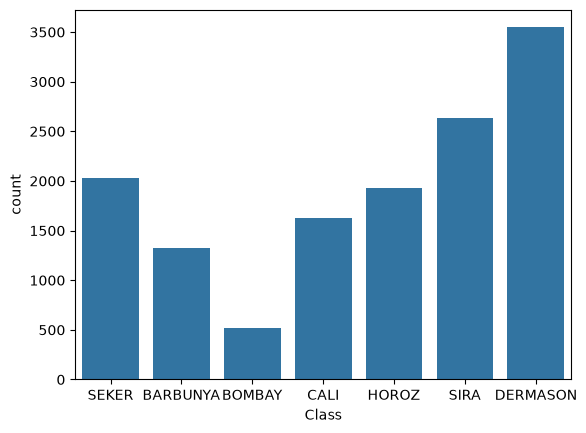

In [62]:
sns.countplot(x='Class', data=data)

# Dataset is NOT balanced. Some classes have more samples than others ex: SEKER has 2000 samples while BOMBAY has 500 samples.

In [63]:
# Part 2: Data Preprocessing:
print(data.isnull().sum()) # No missing values

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64


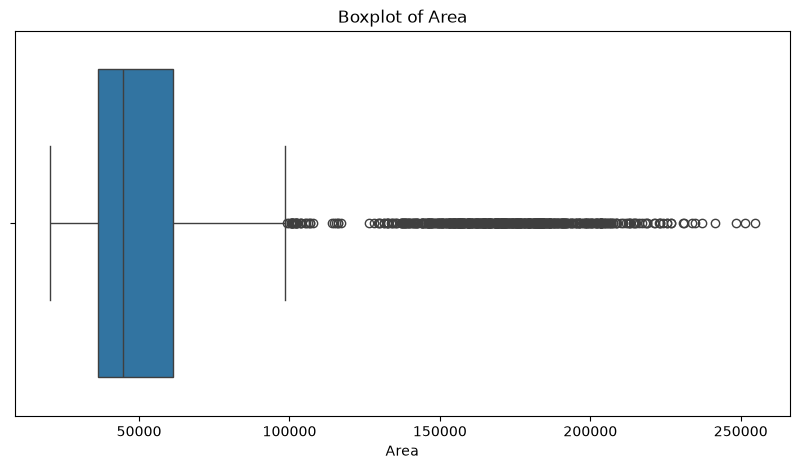

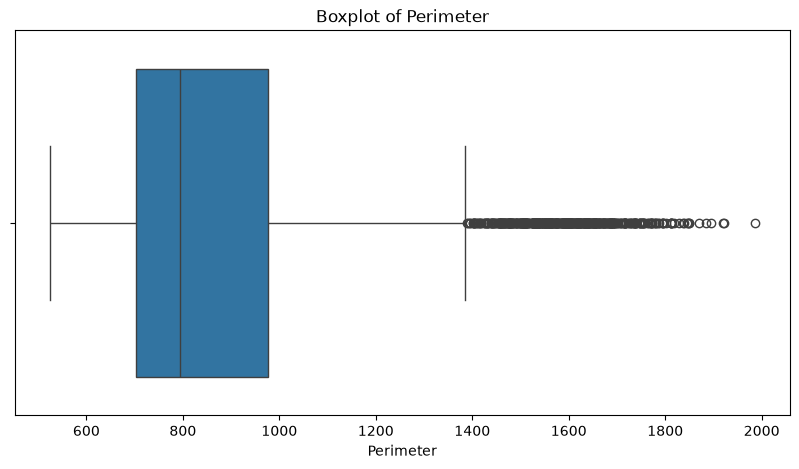

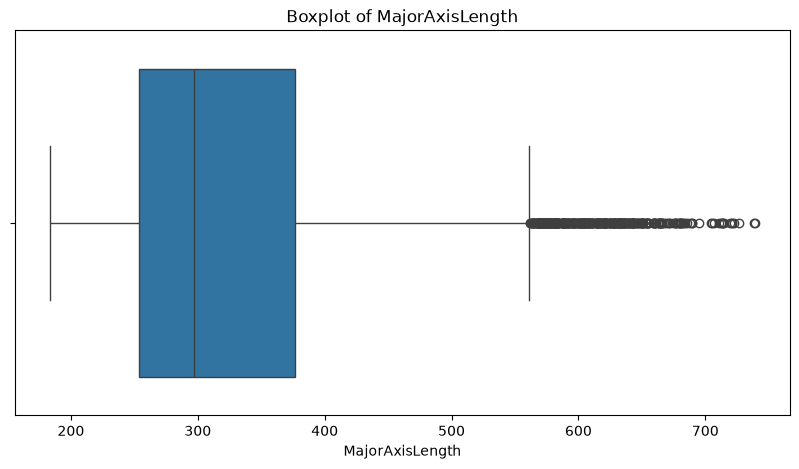

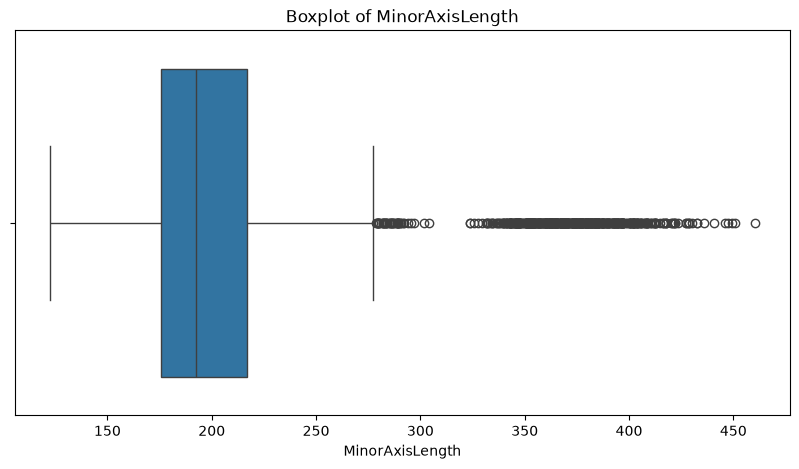

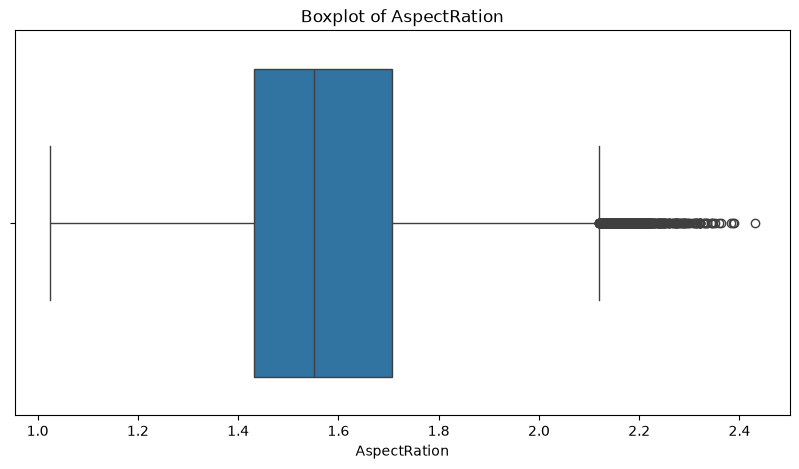

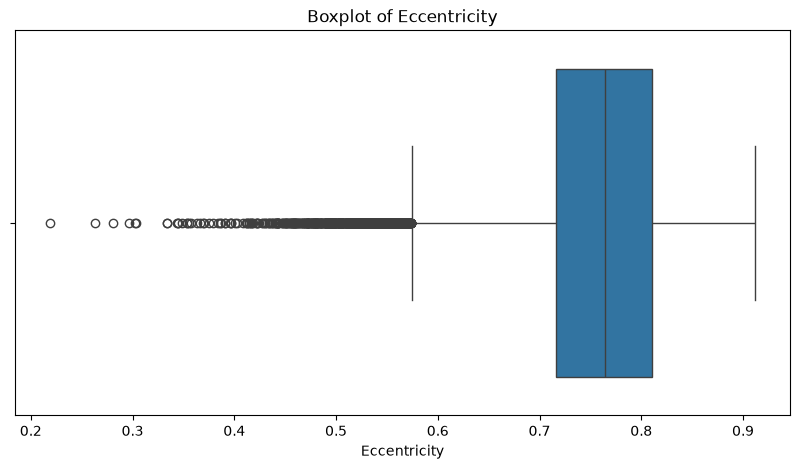

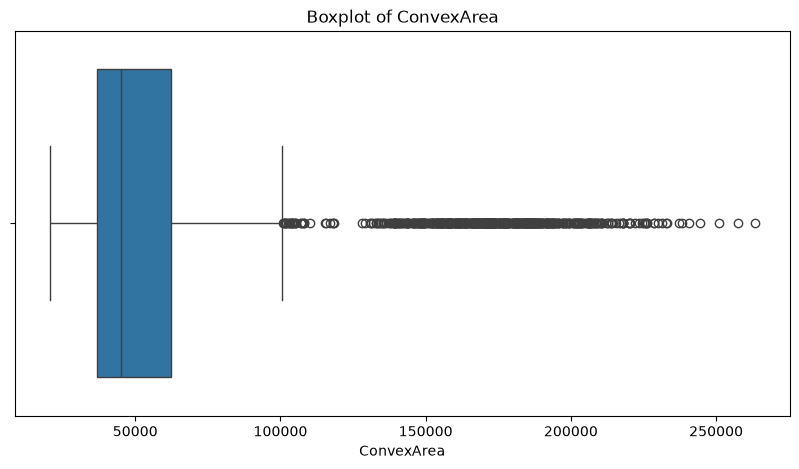

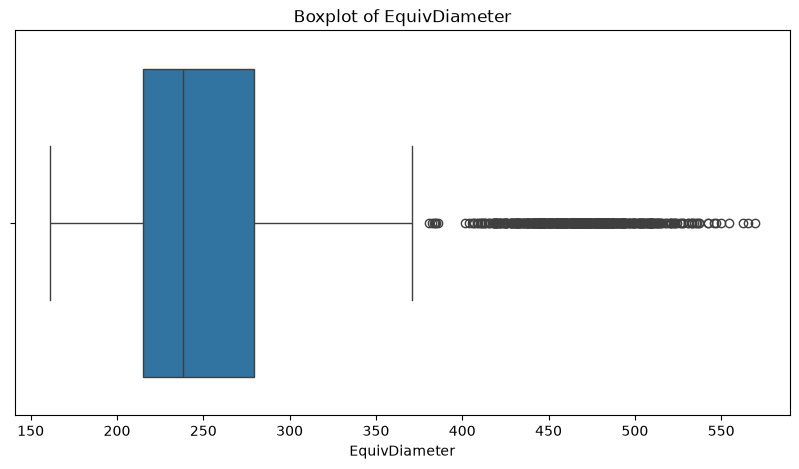

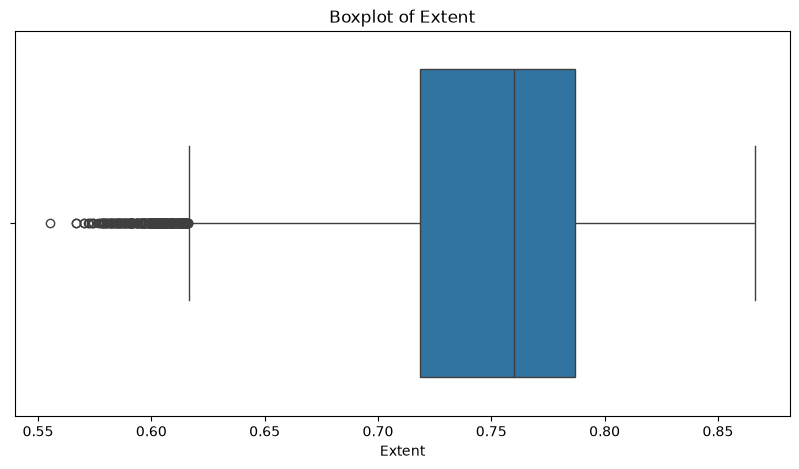

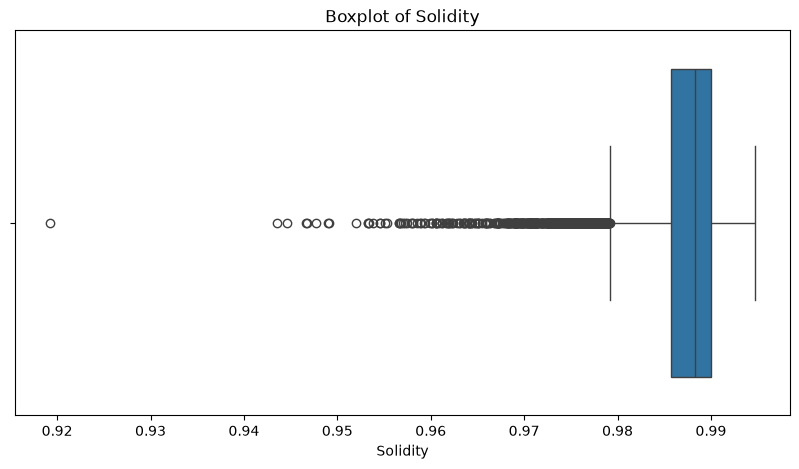

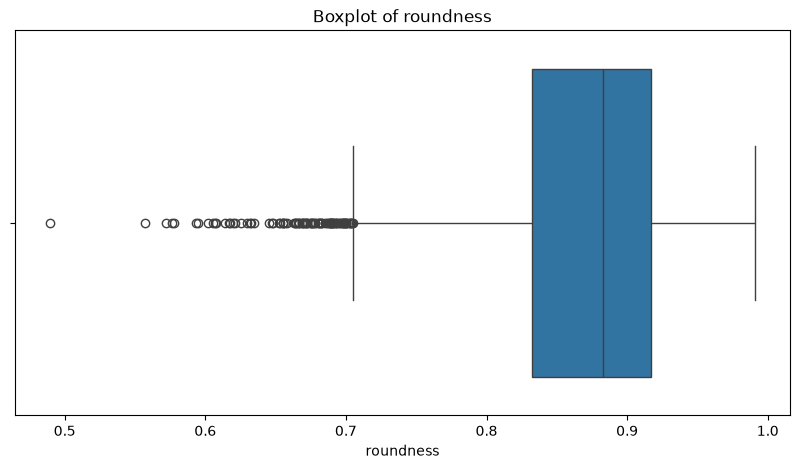

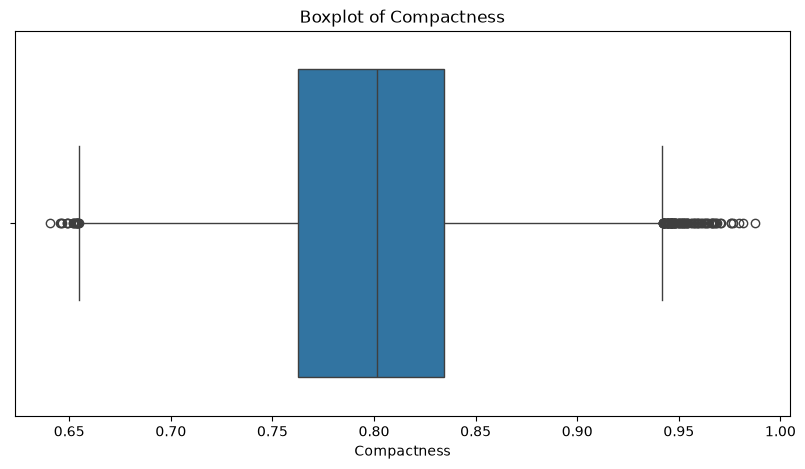

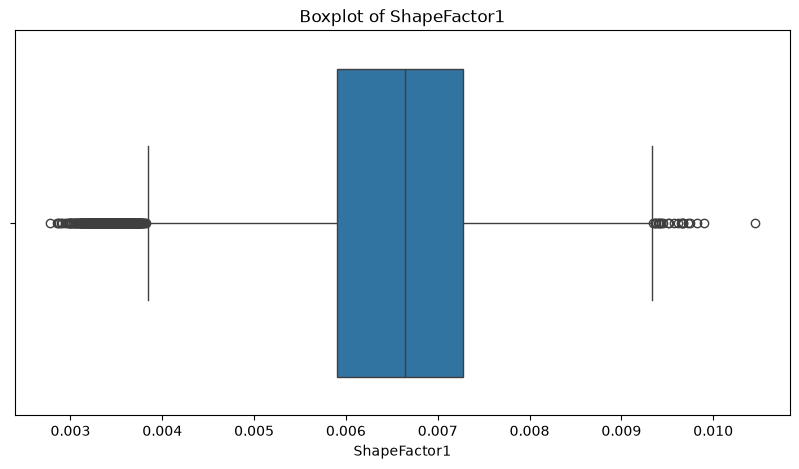

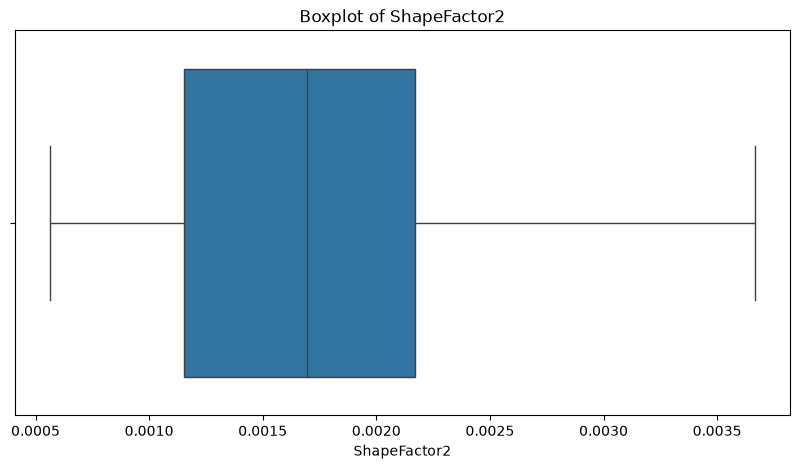

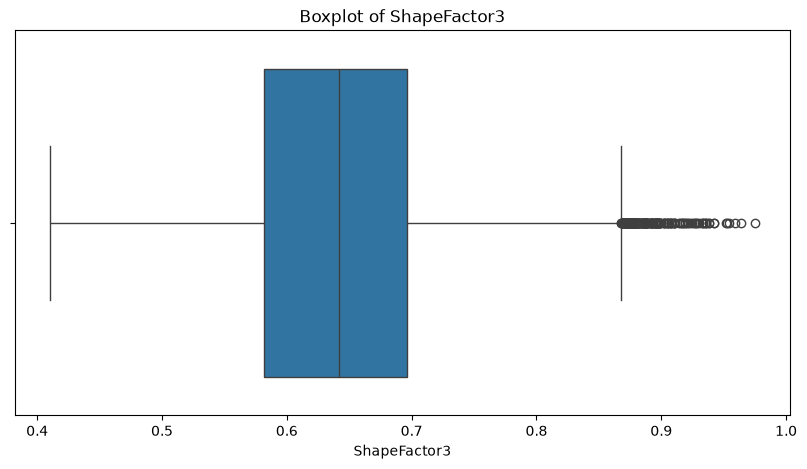

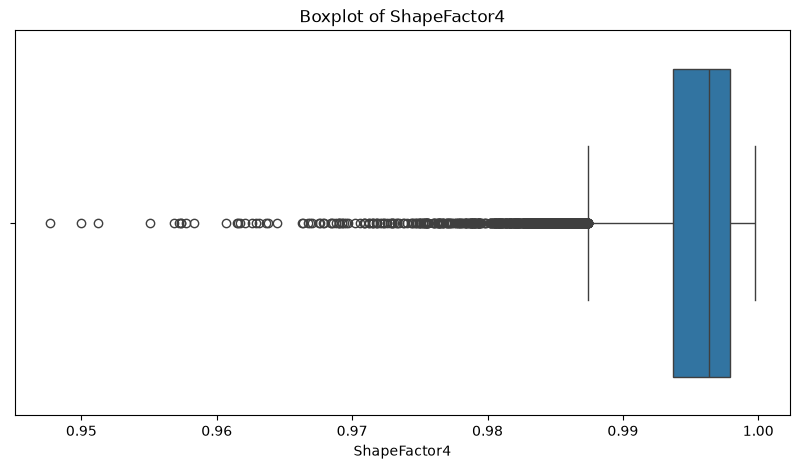

In [64]:
# detecting outliers using boxplot

for column in data.columns[:-1]: # excluding the target column
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=data[column])
    plt.title(f'Boxplot of {column}')
    plt.show()

In [65]:
print(data.shape) # shape before dropping outliers
for column in data.columns[:-1]: # excluding the target column
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    data = data[(data[column] >= lower_bound) & (data[column] <= upper_bound )] # dropping outliers
    
print(data.shape) # shape after dropping outliers

(13611, 17)
(10344, 17)


In [66]:
# Compare between No Scaling and Standard Scaling

"""
No scaling means data is used in its original form without any transformation. so the features may have different ranges and units, which makes the model biased towards features with larger ranges. Standard scaling means data is transformed to have a mean of 0 and a standard deviation of 1. This ensures that all features are on the same scale.
"""

# 4. Explain why feature scaling significantly affects KNN performance.

"""
because KNN is a distance-based algorithm, it calculates the distance between data points to determine their similarity. If the features have different scales, the distance calculation will be biased by features with larger ranges, which leads to wrong results.
"""

'\nbecause KNN is a distance-based algorithm, it calculates the distance between data points to determine their similarity. If the features have different scales, the distance calculation will be biased by features with larger ranges, which leads to wrong results.\n'

In [67]:
# Part 3: Train–Test Strategy:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
features = data.drop("Class", axis=1)
target = data["Class"]
Xtrain, Xtest, Ytrain, Ytest = train_test_split(features, target, test_size=0.2, random_state=42)

print(Xtrain.shape, Xtest.shape, Ytrain.shape, Ytest.shape) # 80% training and 20% testing

scalar = StandardScaler()

Xtrain_scaled = scalar.fit_transform(Xtrain)
Xtest_scaled = scalar.transform(Xtest)

(8275, 16) (2069, 16) (8275,) (2069,)


In [68]:
# Part 4: KNN Implementation & Hyperparameter Tuning:

from sklearn.neighbors import KNeighborsClassifier
knn_model = KNeighborsClassifier(n_neighbors=5) # default k=5

knn_model.fit(Xtrain_scaled, Ytrain)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](6,)","['BARBUNYA','CALI','DERMASON','HOROZ','SEKER','SIRA']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [69]:
ypred = knn_model.predict(Xtest_scaled)

In [72]:
from sklearn.metrics import confusion_matrix, accuracy_score,f1_score

print("Accuracy:", accuracy_score(Ytest, ypred))
print("F1-Score:", f1_score(Ytest, ypred, average='weighted'))

Accuracy: 0.903334944417593
F1-Score: 0.9032903199847964


In [74]:
# Hyperparameter tuning 

k_values = list(range(1, 26))
accuracy_scores = []
for i in k_values:
    knn_model = KNeighborsClassifier(n_neighbors=i)
    knn_model.fit(Xtrain_scaled, Ytrain)
    ypred = knn_model.predict(Xtest_scaled)
    accuracy = accuracy_score(Ytest, ypred)
    accuracy_scores.append(accuracy)
    print(f"Accuracy for k={i}: {accuracy}")
    print(f"F1-Score for k={i}: {f1_score(Ytest, ypred, average='weighted')}")
    

Accuracy for k=1: 0.8854519091348477
F1-Score for k=1: 0.8853245266772035
Accuracy for k=2: 0.8844852585790237
F1-Score for k=2: 0.8833163743452911
Accuracy for k=3: 0.8980183663605606
F1-Score for k=3: 0.8979931874377078
Accuracy for k=4: 0.9072015466408894
F1-Score for k=4: 0.9068629863871646
Accuracy for k=5: 0.903334944417593
F1-Score for k=5: 0.9032903199847964
Accuracy for k=6: 0.9115514741420976
F1-Score for k=6: 0.9113205024555138
Accuracy for k=7: 0.9052682455292412
F1-Score for k=7: 0.9052919409675032
Accuracy for k=8: 0.9130014499758338
F1-Score for k=8: 0.9127884336739427
Accuracy for k=9: 0.9101014983083615
F1-Score for k=9: 0.9100808429087972
Accuracy for k=10: 0.9105848235862736
F1-Score for k=10: 0.9104878434889755
Accuracy for k=11: 0.9110681488641856
F1-Score for k=11: 0.9110738693152114
Accuracy for k=12: 0.9110681488641856
F1-Score for k=12: 0.9109440499274475
Accuracy for k=13: 0.9120347994200096
F1-Score for k=13: 0.9120352839438356
Accuracy for k=14: 0.9120347994

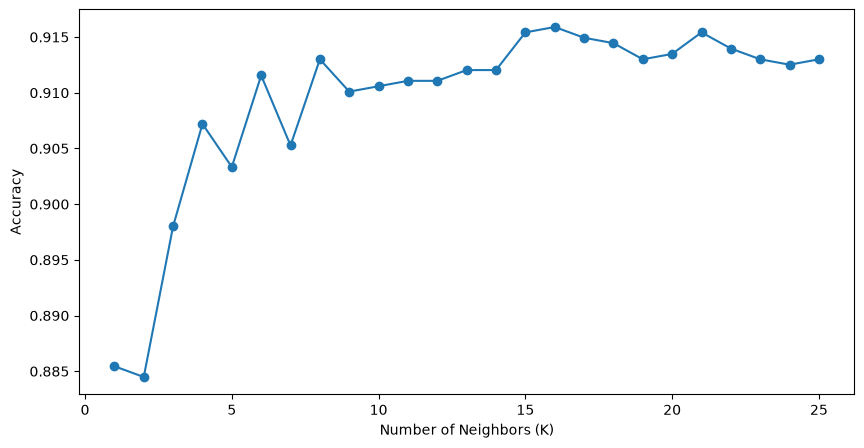

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(k_values, accuracy_scores, marker='o')
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.show()

"""
The optimal value of k is the one that gives the highest accuracy. k=17 satisfies this condition.
"""

In [ ]:
"""
3. Compare different distance metrics:
o Euclidean
o Manhattan
4. Discuss when Manhattan distance might outperform Euclidean distance.

Euclidean Distance: Calculates the straight-line shortest path between two points. It uses the square root of the sum of squared differences between coordinates.

Manhattan Distance: Calculates the distance along grid-like axes. It uses the sum of absolute differences between coordinates.

Manhattan distance might outperform Euclidean distance in high-dimensional spaces or when the data contains outliers.
"""

<Axes: >

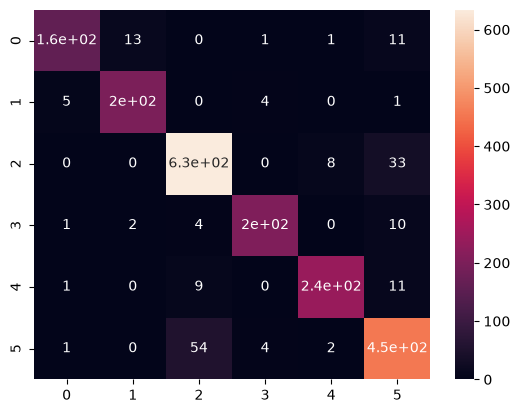

In [79]:
# Part 5: Confusion Matrix Analysis:
# best performing model, k=17

best_knn_model = KNeighborsClassifier(n_neighbors=17)
best_knn_model.fit(Xtrain_scaled, Ytrain)
ypred = best_knn_model.predict(Xtest_scaled)
sns.heatmap(confusion_matrix(Ytest, ypred), annot=True)